In [1]:
import bw2data as bd
import bw2io as bi
import bw2calc as bc
import bw2analyzer as bwa
import polars as pl 
from tqdm import tqdm

bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")

10:16:17+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [68]:
bd.Database("ecoinvent-3.11-biosphere").search("Carbon")

['Carbon dioxide, fossil' (kilogram, None, ('air',)),
 'Carbon monoxide, fossil' (kilogram, None, ('air',)),
 'Carbon dioxide, non-fossil' (kilogram, None, ('air',)),
 'Carbon monoxide, non-fossil' (kilogram, None, ('air',)),
 'TOC, Total Organic Carbon' (kilogram, None, ('water',)),
 'Carbon dioxide, fossil' (kilogram, None, ('air', 'lower stratosphere + upper troposphere')),
 'Carbon monoxide, fossil' (kilogram, None, ('air', 'lower stratosphere + upper troposphere')),
 'Carbon dioxide, from soil or biomass stock' (kilogram, None, ('air',)),
 'Carbon dioxide, in air' (kilogram, None, ('natural resource', 'in air')),
 'TOC, Total Organic Carbon' (kilogram, None, ('water', 'ocean')),
 'Carbon monoxide, from soil or biomass stock' (kilogram, None, ('air',)),
 'TOC, Total Organic Carbon' (kilogram, None, ('water', 'ground-')),
 'Carbon dioxide, to soil or biomass stock' (kilogram, None, ('soil',)),
 'Carbon dioxide, to soil or biomass stock' (kilogram, None, ('soil', 'agricultural')),
 '

In [2]:
gwps = [m for m in bd.methods if "gwp" in str(m).lower() and "no LT" not in str(m) and "EF v3.1" in str(m) and "fossil" not in str(m) and "biogenic" not in str(m) and "land" not in str(m)]
gwps

[('ecoinvent-3.11',
  'EF v3.1',
  'climate change',
  'global warming potential (GWP100)'),
 ('ecoinvent-3.11',
  'EN15804+A2 - Core impact categories and indicators',
  'climate change: total (EF v3.1 - IPCC 2021)',
  'global warming potential (GWP100)')]

In [2]:
bd.databases

Databases dictionary with 11 object(s):
	2026-3-19-11h18_processes_RE2020
	2026-4-21_consumptions_processes
	2026-4-22-15h1_buildings_RE2020
	2026-4-22-16h25_archetypes_RE2020_BB
	2026-4-22-16h7_buildings_cons_RE2020
	2026-4-23-18h10_archetypes_RE2020_PRB
	2026-5-7-20h29_archetypes_RE2020_MIB
	2026-5-7-20h29_bernoulli_RE2020
	ecoinvent-3.11-biosphere
	ecoinvent-3.11-cutoff
	pr_based_arch_alamain

In [6]:
arch_db=bd.Database("2026-4-23-18h10_archetypes_RE2020_PRB")

In [7]:
a = arch_db.random()
# list(list(a.technosphere())[0].input.technosphere())[0].as_dict()

In [8]:
list(a.production())

[Exchange: 8400401.200000001 m2 'Maison_individuelle_ou_accolée' (m2, FR, None) to 'Maison_individuelle_ou_accolée' (m2, FR, None)]

In [13]:
list(a.technosphere())[10]["sous_lot_ref"]

1.0

In [29]:
lca = bc.LCA(demand={a :1.0}, method=gwps[0])
lca.lci()
lca.lcia()

In [30]:
lca.characterized_inventory

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 21609 stored elements and shape (3238, 25792)>

In [32]:
def contribution_analysis_lots(process, ind = (
        'ecoinvent-3.11',
        'EF v3.1',
        'climate change',
        'global warming potential (GWP100)'
        )
        ) :

    lca = bc.LCA(demand = {process : 1.0}, method = ind)
    lca.lci()
    lca.lcia()


    EF_nodes = [str(bd.get_node(id = i)) for i in lca.dicts.biosphere.keys()] # On crée la liste des noeuds (flux élémentaires) à partir de leurs indices
    total_inv_array = lca.inventory.sum(axis=1).A1 # A1 applatit la matrice : ça va plus vite
    total_inventaire = dict(zip(EF_nodes, total_inv_array))
    s = lca.score

    #Conv en strings avant la boucle
    process_str = str(process)
    ind_str = str(ind)

    exchanges = [exc for exc in process.edges() if exc["type"] != "production"]

    dfs = []

    for e in tqdm(exchanges) :
        input_node = e["input"]
        a = bd.get_node(database = input_node[0],code = input_node[1])

        amount = e["amount"]
        lca.redo_lcia(demand={a.id : amount})


        dfs.append(pl.DataFrame({
            "process": process_str,
            "contrib_to_ef": EF_nodes,
            "contrib_to_ind": ind_str,
            "contrib_of": str(a),
            "lot": str(e["lot_ref"]),
            "sous-lot":str(e["sous_lot_ref"]),
            "inventory_value":lca.inventory.sum(axis=1).A1,
            "charac_inventory_value": lca.characterized_inventory.sum(axis=1).A1,
        }))
    
    res = pl.concat(dfs, rechunk=False)
    
    # on divise les résultats par la valeur de flux de référence

    phi = list(process.production())[0]["amount"]
    res = res.with_columns(
        (pl.col("inventory_value", "charac_inventory_value") / phi))
    res = res.with_columns(
        (pl.col("inventory_value") / pl.col("contrib_to_ef").replace_strict(
            total_inventaire, default=0
        )).alias("relativ_inventory_value"),
        (pl.col("charac_inventory_value") / s).alias("relativ_charac_inventory_value"),
    )
    return res

In [46]:
import matplotlib
sorted([f.name for f in matplotlib.font_manager.fontManager.ttflist])


['Abyssinica SIL',
 'Accanthis ADF Std',
 'Accanthis ADF Std',
 'Accanthis ADF Std',
 'Accanthis ADF Std',
 'Accanthis ADF Std No2',
 'Accanthis ADF Std No2',
 'Accanthis ADF Std No2',
 'Accanthis ADF Std No2',
 'Accanthis ADF Std No3',
 'Accanthis ADF Std No3',
 'Accanthis ADF Std No3',
 'Accanthis ADF Std No3',
 'Andale Mono',
 'Andale Mono',
 'Ani',
 'AnjaliOldLipi',
 'Arial',
 'Arial',
 'Arial',
 'Arial',
 'Arial',
 'Arial',
 'Arial',
 'Arial',
 'Arial Black',
 'Arial Black',
 'Arimo',
 'Arimo',
 'Arimo',
 'Arimo',
 'Asana Math',
 'Berenis ADF Pro',
 'Berenis ADF Pro',
 'Berenis ADF Pro',
 'Berenis ADF Pro',
 'Berenis ADF Pro Math',
 'C059',
 'C059',
 'C059',
 'C059',
 'Cabin',
 'Cabin',
 'Cabin',
 'Cabin',
 'Cabin',
 'Cabin',
 'Cabin',
 'Cabin',
 'Caladea',
 'Caladea',
 'Caladea',
 'Caladea',
 'Cantarell',
 'Cantarell',
 'Cantarell',
 'Cantarell',
 'Cantarell',
 'Carlito',
 'Carlito',
 'Carlito',
 'Carlito',
 'Chandas',
 'Charis SIL',
 'Charis SIL',
 'Charis SIL',
 'Charis SIL',
 

In [33]:
df = contribution_analysis_lots(a)


100%|██████████| 988/988 [00:41<00:00, 24.02it/s]


In [11]:
df["charac_inventory_value"].sum()

782255215.9906693

In [24]:
list(a.production())[0].as_dict()["amount"]

582465.9

In [43]:
df["contrib_to_ef"][0]

"'Flurochloridone' (kilogram, None, ('air', 'non-urban air or from high stacks'))"

In [44]:
df.filter(pl.col("contrib_to_ef")== "'Flurochloridone' (kilogram, None, ('air', 'non-urban air or from high stacks'))")["relativ_inventory_value"].fill_nan(0).sum()

0.999999998989485

In [36]:
df.group_by("lot").sum()

lot,process,contrib_to_ef,contrib_to_ind,contrib_of,sous-lot,inventory_value,charac_inventory_value,relativ_inventory_value,relativ_charac_inventory_value
str,str,str,str,str,str,f64,f64,f64,f64
"""9""",null,null,null,null,null,805.170886,9.652994,NaN,0.007851
"""3""",null,null,null,null,null,7756.500694,189.518793,NaN,0.154142
"""7""",null,null,null,null,null,4286.973487,56.833971,NaN,0.046225
"""Consommations_bois""",null,null,null,null,null,9891.197399,29.475587,NaN,0.023974
"""8""",null,null,null,null,null,1045.556999,31.697046,NaN,0.02578
…,…,…,…,…,…,…,…,…,…
"""Consommations_gaz""",null,null,null,null,null,10743.853489,280.608519,NaN,0.228229
"""13""",null,null,null,null,null,2024.394635,18.421872,NaN,0.014983
"""consommations_electricite""",null,null,null,null,null,647449.674246,126.387957,NaN,0.102796


In [19]:
nodes = [bd.get_node(id = i) for i in lca.dicts.biosphere.keys()] # On crée la liste des noeuds (flux élémentaires) à partir de leurs indices
contrib_EF_dict = {str(nodes[i]):float(contrib_EF[i,0]) for i in range(len(nodes))} 

In [104]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import polars as pl
from archetypes_re2020.utils.utils import LOTS, SOUS_LOTS

# Nord palette — accent colors Nord7 to Nord15
NORD_PALETTE = [
    "#8FBCBB",  # Nord7  - teal
    "#88C0D0",  # Nord8  - light blue
    "#81A1C1",  # Nord9  - blue
    "#5E81AC",  # Nord10 - dark blue
    "#BF616A",  # Nord11 - red
    "#D08770",  # Nord12 - orange
    "#EBCB8B",  # Nord13 - yellow
    "#A3BE8C",  # Nord14 - green
    "#B48EAD",  # Nord15 - purple
]
NORD_CUTOFF_COLOR = "#d8dee9"

def get_used_label(label: str, contrib_of: str, translate_dict: dict) -> str:
    if contrib_of not in ("lot", "sous-lot"):
        return label
    if isinstance(label, str) and "consommations" in label.lower():
        return label
    return translate_dict.get(label, label)

def stackbars_plot(
    to_graph,
    contrib_of: str,
    contrib_to: str,
    cutoff: float = 0.02,       # relative threshold: groups segments below X% of total
    figsize: tuple = (8, 4),
    bar_width = 0.8
):
    plt.rcParams.update({
        "text.usetex": True,
        "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
        "font.family": "serif",
        "font.serif": "Computer Modern",
        "savefig.bbox": "tight",
        "savefig.format": "pdf",
    })

    translate_dict = {}
    if contrib_of == "lot":
        translate_dict = LOTS
    elif contrib_of == "sous-lot":
        translate_dict = SOUS_LOTS

    to_graph_sorted = (
        to_graph
        .group_by(contrib_of)
        .agg(pl.col(contrib_to).sum())
        .sort(contrib_to, descending=True)
    )

    labels = to_graph_sorted[contrib_of].to_list()
    values = to_graph_sorted[contrib_to].to_list()
    total = sum(abs(v) for v in values)

    # Split into main segments and below-cutoff group
    main_labels, main_values = [], []
    cutoff_labels, cutoff_values = [], []

    for label, value in zip(labels, values):
        if abs(value) / total < cutoff:
            cutoff_labels.append(get_used_label(label, contrib_of, translate_dict))
            cutoff_values.append(value)
        else:
            main_labels.append(label)
            main_values.append(value)

    # Append the grouped "below cut-off" segment at the end (smallest, so top of stack)
    if cutoff_labels:
        main_labels.append("_cutoff")
        main_values.append(sum(cutoff_values))

    colors = [NORD_PALETTE[j % len(NORD_PALETTE)] for j in range(len(main_labels))]

    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)

    bottom_pos, bottom_neg = 0.0, 0.0
    legend_entries = []

    for j, (label, value) in enumerate(zip(main_labels, main_values)):
        bottom = bottom_pos if value >= 0 else bottom_neg
        is_cutoff = label == "_cutoff"
        color = NORD_CUTOFF_COLOR if is_cutoff else colors[j]
        display_label = f"Sous le seuil de {cutoff}" if is_cutoff else get_used_label(label, contrib_of, translate_dict)

        ax.bar(
            0, value, bar_width,
            bottom=bottom,
            color=color,
            edgecolor="white",
            linewidth=0.6,
            alpha=1.0,
        )
        legend_entries.append(mpatches.Patch(color=color, label=display_label))

        if value >= 0:
            bottom_pos += value
        else:
            bottom_neg += value

    ax.set_xlim(-1, 1)
    ax.set_xticks([])
    ax.axhline(0, color="#2E3440", linewidth=0.8, linestyle="--", alpha=0.5)

    # Legend: reversed to match visual top → bottom reading
    legend = ax.legend(
        handles=legend_entries[::-1],
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        frameon=False,
    )

    # Annotation below legend listing the cut-off labels
    if cutoff_labels:
        cutoff_text = f"Sous le seuil de {cutoff}"+ "\n" + "\n".join(
            rf"$\bullet$ {l} : {v:.2f}" for l, v in zip(cutoff_labels, cutoff_values)
        )
        ax.annotate(
            cutoff_text,
            xy=(1.05, 0),
            xycoords="axes fraction",
            fontsize=7,
            color="#4C566A",
            va="bottom",
            ha="left",
        )
    
    ax.set_ylabel(f"{contrib_to}")
    ax.set_title(to_graph["process"].unique()[0])
    

    return fig, ax

(<Figure size 800x400 with 1 Axes>,
 <Axes: title={'center': "'Enseignement_primaire' (m2, FR, None)"}, ylabel='relativ_charac_inventory_value'>)

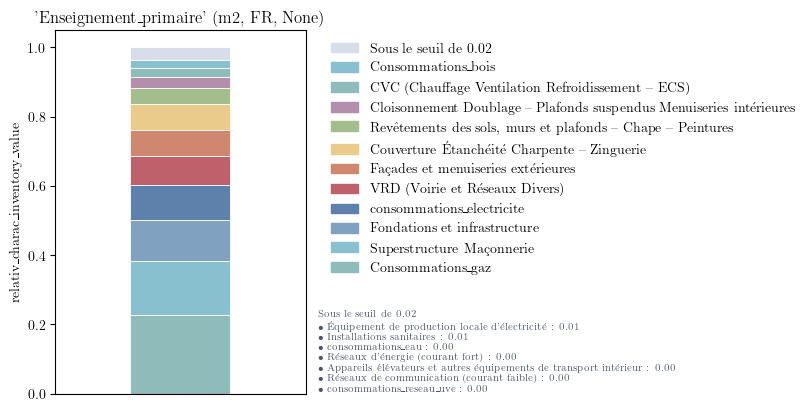

In [105]:
stackbars_plot(df,"lot","relativ_charac_inventory_value")

In [20]:
contrib_EF_dict

{"'Flurochloridone' (kilogram, None, ('air', 'non-urban air or from high stacks'))": 4.9306363276225616e-12,
 "'Phenol' (kilogram, None, ('water', 'ocean'))": 0.0006416380573787785,
 "'Solids, inorganic' (kilogram, None, ('water', 'ground-'))": 0.20529292010669015,
 "'Prothioconazole' (kilogram, None, ('water', 'surface water'))": 1.1243931069948428e-14,
 "'Sulfadiazine' (kilogram, None, ('water',))": 5.964933523149224e-10,
 "'Pentachlorobenzene' (kilogram, None, ('air', 'non-urban air or from high stacks'))": 1.1190072691883283e-11,
 "'Azinphos-methyl' (kilogram, None, ('soil', 'agricultural'))": 3.262029716123799e-08,
 "'Monochloroethane' (kilogram, None, ('water', 'surface water'))": 0.0,
 "'Thiobencarb' (kilogram, None, ('soil', 'agricultural'))": 3.702293755400677e-09,
 "'Carbon' (kilogram, None, ('water', 'ground-'))": 6.343674138484725e-05,
 "'m-Xylene' (kilogram, None, ('air', 'non-urban air or from high stacks'))": 4.4495669128242155e-09,
 "'Transformation, to dump site' (squa

In [17]:
lots = {
    1: "VRD (Voirie et Réseaux Divers)",
    2: "Fondations et infrastructure",
    3: "Superstructure Maçonnerie",
    4: "Couverture Étanchéité Charpente – Zinguerie",
    5: "Cloisonnement Doublage – Plafonds suspendus Menuiseries intérieures",
    6: "Façades et menuiseries extérieures",
    7: "Revêtements des sols, murs et plafonds – Chape – Peintures",
    8: "CVC (Chauffage Ventilation Refroidissement – ECS)",
    9: "Installations sanitaires",
    10: "Réseaux d’énergie (courant fort)",
    11: "Réseaux de communication (courant faible)",
    12: "Appareils élévateurs et autres équipements de transport intérieur",
    13: "Équipement de production locale d’électricité",
}

sous_lots = {
    "1.1": "Réseaux (extérieurs, jusqu’au domaine public)",
    "1.2": "Stockage",
    "1.3": "Aires de stationnement extérieures",
    "2.1": "Fondations",
    "2.2": "Murs et structures enterrées (escalier de cave, parc de stationnement…)",
    "2.3": "Parcs de stationnement en superstructure (hors garages individuels)",
    "3.1": "Éléments horizontaux – Planchers, dalles, balcons",
    "3.2": "Éléments horizontaux – Poutres",
    "3.3": "Éléments verticaux – Façades",
    "3.4": "Éléments verticaux – Refends",
    "3.5": "Éléments verticaux – Poteaux",
    "3.6": "Escaliers et rampes",
    "3.7": "Éléments d’isolation",
    "3.8": "Maçonneries diverses (appuis de baie)",
    "4.1": "Toitures terrasses",
    "4.2": "Toitures en pente",
    "4.3": "Éléments techniques de toiture (cheminées, lanterneaux, etc.)",
    "5.1": "Cloisons et portes intérieures",
    "5.2": "Doublages mur, matériaux de protection, isolants et membranes",
    "5.3": "Plafonds suspendus",
    "5.4": "Planchers surélevés",
    "5.5": "Menuiseries, métalleries et quincailleries",
    "6.1": "Revêtement, isolation et doublage extérieur",
    "6.2": "Portes, fenêtres, fermetures, protections solaires",
    "6.3": "Habillages et ossatures",
    "7.1": "Revêtement des sols",
    "7.2": "Revêtement des murs et plafonds",
    "7.3": "Éléments de décoration et revêtements des menuiseries",
    "8.1": "Équipements de production (chaud/froid) – hors cogénération",
    "8.2": "Systèmes de cogénération",
    "8.3": "Systèmes d’émission",
    "8.4": "Traitement de l’air et éléments de désenfumage",
    "8.5": "Réseaux et conduits",
    "8.6": "Stockage (combustibles)",
    "8.7": "Fluides frigorigènes",
    "9.1": "Éléments sanitaires et robinetterie",
    "9.2": "Canalisations, réseaux et systèmes de traitement",
    "10.1": "Réseaux électriques",
    "10.2": "Ensemble de dispositifs pour la sécurité",
    "10.3": "Éclairage intérieur (général)",
    "10.4": "Éclairage extérieur",
    "10.5": "Systèmes d’automatisation et de contrôle",
    "10.6": "Tableaux et appareillages",
    "11.1": "Réseaux électriques et de communications",
    "11.2": "Systèmes de sécurité (personnes et biens)",
    "11.3": "Installations techniques et appareillages",
    "12.1": "Ascenseurs, monte‑charges, escaliers mécaniques, nacelles de nettoyage",
    "13.1": "Installation dédiée à la production d’électricité (panneaux, onduleur, etc.)",
}


In [19]:
bwa.print_recursive_calculation(activity=a, lcia_method=gwps[0])

Fraction of score | Absolute score | Amount | Activity
0001 |  1230 |     1 | 'Enseignement_primaire' (m2, FR, None)
  0.0183 | 22.56 | 0.05766 | 'Fondations _Béton non armé' (m³, FR, ('custom_process',))
    0.0162 | 19.93 | 0.05766 | 'market for concrete, 40MPa' (cubic meter, RoW, None)
      0.012 | 14.72 | 0.04555 | 'concrete production, 40MPa, for civil engineering, with cement, CEM II/B' (cubic meter, GLO, None
  0.0291 | 35.79 | 0.1094 | 'Fenêtres / portes fenêtres_Aluminium' (m², FR, ('custom_process',))
    0.0118 | 14.53 | 0.02188 | 'market for window frame, aluminium, U=1.6 W/m2K' (square meter, GLO, None)
    0.0118 | 14.53 | 0.02188 | 'market for window frame, aluminium, U=1.6 W/m2K' (square meter, GLO, None)
  0.0309 | 37.94 | 431.2 | 'Consommations_électricité' (kilowatt hour, FR, ('custom_process',))
    0.0309 | 37.94 | 431.2 | 'market for electricity, low voltage' (kilowatt hour, FR, None)
      0.0275 | 33.76 | 422.3 | 'electricity voltage transformation from medium 

KeyboardInterrupt: 

In [ ]:
import polars as pl

results_df = to_graph = pl.DataFrame(schema={"usage" : pl.String,"score" : pl.Float64,"indicateur" : pl.String,"procédé" : pl.String,**{k : pl.String for k in init}})

for arch,d_contrib in contrib_proc.items() :
    for p,s in d_contrib.items():
        new_row = pl.DataFrame(
            {
                "usage": str(arch),
                "score" : s,
                "indicateur" : "GWP100",
                "procédé" : p["name"],
                **{ k : v for k,v in p.as_dict().items() if "nomenc" in k}
            }
            )
        to_graph.extend(new_row)

In [9]:
[str(p) for p, _ in zip(arch_db,range(10))]

["'Bureau' (m2, FR, None)",
 "'Enseignement_primaire' (m2, FR, None)",
 "'Enseignement_secondaire_(partie_jour)' (m2, FR, None)",
 "'Maison_individuelle_ou_accolée' (m2, FR, None)",
 "'Logement_collectif' (m2, FR, None)"]